# 25 — Week 7: SHAP explanation of the frozen LightGBM models (validation)

**Plan item:** SHAP on LightGBM and the ten most important features.

**Design (provisional).**
- The frozen LightGBM models (notebook 08 tuned parameters and rounds, refit on train, seed 0) are re-created with
  `src/evaluation/frozen.py` settings; cell 2 checks that they reproduce the stored validation forecasts before any
  explanation is computed.
- Exact TreeSHAP values from LightGBM itself (`pred_contrib=True`); the `shap` package is used only for the beeswarm
  plot. The models predict the **change** P(t+h) − P(t), so a SHAP value is a contribution in kW to the predicted change.
- Explained origins: **validation only** (the test split is not needed for an explanation): a random sample of 6,000
  usable origins (global importance) plus all ramp origins (ramp vs normal comparison).
- Features are also grouped (recent lags 1–5, older lags 6–59, five-minute phase, hour, level, GPU-count changes,
  memory changes, utilisation/temperature changes, queue/job changes, allocation gap) so the 92 inputs can be read
  as a few physical drivers.
- Both arms: `lightgbm_cov` (92 features) and `lightgbm` (67, univariate).

Run all cells in order (about 5 min), save with Cmd+S, then run the last cell (export).


In [1]:
# Cell 1: setup and package check
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
from evaluation import frozen as FZ

print("lightgbm", lgb.__version__, "| shap", shap.__version__, "| numpy", np.__version__)
HORIZONS = FZ.HORIZONS
ARMS = {"lightgbm_cov": "gbm_cov", "lightgbm": "gbm"}
REP, FIG = ROOT / "reports" / "week7", ROOT / "reports" / "figures" / "week7"
REP.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
N_SAMPLE, SEED = 6000, 0
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6})
c = FZ.Ctx(ROOT)
md_ = c.md
print("usable validation origins:", {h: len(c.IDX[h]["val"]) for h in HORIZONS})

def group_of(name):
    if name.startswith("lag"):
        return "lags 1-5" if int(name[3:]) <= 5 else "lags 6-59"
    if name.startswith("mod5_"):
        return "five-minute phase"
    if name.startswith("hour_"):
        return "hour of day"
    if name in ("level_rel_L24", "L24"):
        return "level (L24)"
    if name == "alloc_gap":
        return "allocation gap"
    if any(k in name for k in ("n_gpu_equiv", "gpus_alloc", "active_gpu_jobs")):
        return "GPU-count changes"
    if "util_" in name or "temp_" in name:
        return "util / temp changes"
    if "mem_" in name:
        return "memory changes"
    return "queue / job changes"


/opt/miniconda3/envs/dcpower/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


lightgbm 4.7.0 | shap 0.51.0 | numpy 2.4.6
usable validation origins: {1: 42575, 5: 42567, 15: 42547}


In [2]:
# Cell 2: re-create the frozen LightGBM models (seed 0) and check them against the stored validation forecasts
stored = pl.read_parquet(ROOT / "reports" / "classical" / "val_predictions.parquet")
BOOST, NAMES, REPRO = {}, {}, []
t0 = time.time()
for h in HORIZONS:
    tr, va = c.IDX[h]["train"], c.IDX[h]["val"]
    for model, arm in ARMS.items():
        tune = c.clas["lightgbm"][f"{h}|{arm}"]
        Xtr, names = c.TF.features(c.A, tr, arm)
        dtr = lgb.Dataset(Xtr, c.P[tr + h] - c.P[tr], feature_name=names, params={"feature_pre_filter": False})
        b = lgb.train(FZ._lgb_params(tune["params"], 0), dtr, num_boost_round=max(int(tune["rounds"]), 1))
        BOOST[(model, h)], NAMES[(model, h)] = b, names
        Xva, _ = c.TF.features(c.A, va, arm)
        yhat = c.P[va] + b.predict(Xva)
        ref = stored.filter((pl.col("model") == model) & (pl.col("h") == h)).sort("minute_epoch")["yhat"].to_numpy()
        d = float(np.max(np.abs(yhat - ref))) if len(ref) == len(yhat) else float("inf")
        REPRO.append({"model": model, "h": h, "features": len(names), "rounds": int(tune["rounds"]), "max_abs_diff_kW": d})
    print(f"  h={h:>2}: refit done | {time.time() - t0:.0f} s")
REPRO = pl.DataFrame(REPRO).with_columns((pl.col("max_abs_diff_kW") < 1e-3).alias("ok"))
print(REPRO)
REPRO_OK = bool(REPRO["ok"].all())
print("REPRODUCTION PASSED" if REPRO_OK else "REPRODUCTION FAILED: stop and send this output")


  h= 1: refit done | 38 s
  h= 5: refit done | 68 s
  h=15: refit done | 87 s
shape: (6, 6)
┌──────────────┬─────┬──────────┬────────┬─────────────────┬──────┐
│ model        ┆ h   ┆ features ┆ rounds ┆ max_abs_diff_kW ┆ ok   │
│ ---          ┆ --- ┆ ---      ┆ ---    ┆ ---             ┆ ---  │
│ str          ┆ i64 ┆ i64      ┆ i64    ┆ f64             ┆ bool │
╞══════════════╪═════╪══════════╪════════╪═════════════════╪══════╡
│ lightgbm_cov ┆ 1   ┆ 92       ┆ 966    ┆ 0.0             ┆ true │
│ lightgbm     ┆ 1   ┆ 67       ┆ 692    ┆ 0.0             ┆ true │
│ lightgbm_cov ┆ 5   ┆ 92       ┆ 491    ┆ 0.0             ┆ true │
│ lightgbm     ┆ 5   ┆ 67       ┆ 646    ┆ 0.0             ┆ true │
│ lightgbm_cov ┆ 15  ┆ 92       ┆ 284    ┆ 0.0             ┆ true │
│ lightgbm     ┆ 15  ┆ 67       ┆ 90     ┆ 0.0             ┆ true │
└──────────────┴─────┴──────────┴────────┴─────────────────┴──────┘
REPRODUCTION PASSED


In [3]:
# Cell 3: exact TreeSHAP on validation origins (random sample + all ramp origins); additivity check
assert REPRO_OK
rng = np.random.default_rng(SEED)
SH = {}
for h in HORIZONS:
    va = c.IDX[h]["val"]
    ramp = md_[f"ramp_h{h}"].cast(pl.Float64).to_numpy()[va]
    samp = np.sort(rng.choice(len(va), size=min(N_SAMPLE, len(va)), replace=False))
    rmp = np.flatnonzero(ramp == 1)
    pos = np.union1d(samp, rmp)
    t = va[pos]
    in_sample = np.isin(pos, samp)
    for model, arm in ARMS.items():
        X, names = c.TF.features(c.A, t, arm)
        b = BOOST[(model, h)]
        t1 = time.time()
        contrib = b.predict(X, pred_contrib=True)
        vals, base = contrib[:, :-1], contrib[:, -1]
        pred = b.predict(X)
        add_err = float(np.max(np.abs(vals.sum(1) + base - pred)))
        SH[(model, h)] = {"X": X, "vals": vals, "base": base, "names": names, "ramp": ramp[pos], "sample": in_sample}
        print(f"  {model:13s} h={h:>2}: {len(t):,} origins ({in_sample.sum():,} random, {int((ramp[pos] == 1).sum()):,} ramp) | "
              f"additivity max error {add_err:.2e} kW | {time.time() - t1:.1f} s")
        assert add_err < 1e-6


  lightgbm_cov  h= 1: 7,657 origins (6,000 random, 1,903 ramp) | additivity max error 7.33e-15 kW | 6.3 s
  lightgbm      h= 1: 7,657 origins (6,000 random, 1,903 ramp) | additivity max error 6.66e-15 kW | 11.3 s
  lightgbm_cov  h= 5: 8,086 origins (6,000 random, 2,444 ramp) | additivity max error 7.55e-15 kW | 5.3 s
  lightgbm      h= 5: 8,086 origins (6,000 random, 2,444 ramp) | additivity max error 7.99e-15 kW | 6.7 s
  lightgbm_cov  h=15: 8,315 origins (6,000 random, 2,740 ramp) | additivity max error 3.81e-12 kW | 15.7 s
  lightgbm      h=15: 8,315 origins (6,000 random, 2,740 ramp) | additivity max error 4.88e-15 kW | 1.3 s


In [4]:
# Cell 4: top-10 features (mean |SHAP| on the random sample) and grouped importance
rows, grows = [], []
for (model, h), s in SH.items():
    m = s["sample"]
    imp = np.abs(s["vals"][m]).mean(0)
    tot = imp.sum()
    order = np.argsort(-imp)
    for r, j in enumerate(order[:10], 1):
        rows.append({"model": model, "h": h, "rank": r, "feature": s["names"][j], "mean_abs_shap_kW": float(imp[j]),
                     "share": float(imp[j] / tot), "group": group_of(s["names"][j])})
    g = np.array([group_of(n) for n in s["names"]])
    for lab in ("all", "normal", "ramp"):
        sel = m if lab == "all" else ((s["ramp"] == 0) & m if lab == "normal" else s["ramp"] == 1)
        A = np.abs(s["vals"][sel])
        for grp in np.unique(g):
            grows.append({"model": model, "h": h, "steps": lab, "group": grp, "n": int(sel.sum()),
                          "mean_abs_shap_kW": float(A[:, g == grp].sum(1).mean())})
TOP = pl.DataFrame(rows)
GRP = pl.DataFrame(grows).with_columns((pl.col("mean_abs_shap_kW") / pl.col("mean_abs_shap_kW").sum().over("model", "h", "steps")).alias("share"))
TOP.write_csv(REP / "shap_top10_val.csv"); GRP.write_csv(REP / "shap_groups_val.csv")
pl.Config.set_tbl_rows(70); pl.Config.set_tbl_width_chars(200)
print("=== top-10 features, lightgbm_cov (mean |SHAP| in kW of predicted change; validation sample) ===")
print(TOP.filter(pl.col("model") == "lightgbm_cov").with_columns(pl.col("mean_abs_shap_kW").round(4), pl.col("share").round(3))
      .pivot(on="h", index="rank", values="feature").rename({"1": "h=1", "5": "h=5", "15": "h=15"}))
print(TOP.filter(pl.col("model") == "lightgbm_cov").select("h", "rank", "feature", "group", pl.col("mean_abs_shap_kW").round(4), pl.col("share").round(3)))
print("\n=== top-10 features, lightgbm (univariate) ===")
print(TOP.filter(pl.col("model") == "lightgbm").pivot(on="h", index="rank", values="feature"))
print("\n=== grouped share of mean |SHAP| (random sample) ===")
print(GRP.filter(pl.col("steps") == "all").with_columns(pl.col("share").round(3), (pl.col("model") + " h" + pl.col("h").cast(pl.Utf8)).alias("k"))
      .pivot(on="k", index="group", values="share").sort("group"))


=== top-10 features, lightgbm_cov (mean |SHAP| in kW of predicted change; validation sample) ===
shape: (10, 4)
┌──────┬──────────────────┬──────────────────┬────────────────────┐
│ rank ┆ h=1              ┆ h=5              ┆ h=15               │
│ ---  ┆ ---              ┆ ---              ┆ ---                │
│ i64  ┆ str              ┆ str              ┆ str                │
╞══════╪══════════════════╪══════════════════╪════════════════════╡
│ 1    ┆ lag4             ┆ d5_util_gpu_mean ┆ d5_util_gpu_mean   │
│ 2    ┆ mod5_4           ┆ lag3             ┆ L24                │
│ 3    ┆ lag1             ┆ lag2             ┆ lag3               │
│ 4    ┆ lag2             ┆ lag1             ┆ lag4               │
│ 5    ┆ d5_mem_used_sum  ┆ lag4             ┆ lag2               │
│ 6    ┆ lag3             ┆ lag10            ┆ d5_mem_used_sum    │
│ 7    ┆ d1_temp_mem_mean ┆ d5_mem_used_sum  ┆ d5_n_gpu_equiv     │
│ 8    ┆ L24              ┆ d5_n_gpu_equiv   ┆ level_rel_L24      │
│ 9 

In [5]:
# Cell 5: ramp vs normal steps: which drivers grow at ramps; agreement with LightGBM gain importance
cmp_ = (GRP.filter(pl.col("steps") != "all").pivot(on="steps", index=["model", "h", "group"], values="mean_abs_shap_kW")
          .with_columns((pl.col("ramp") / pl.col("normal")).alias("ramp_over_normal")).sort("model", "h", "group"))
cmp_.write_csv(REP / "shap_ramp_vs_normal_val.csv")
print("=== mean |SHAP| (kW) on normal vs ramp steps, lightgbm_cov ===")
print(cmp_.filter(pl.col("model") == "lightgbm_cov").with_columns(pl.col(pl.Float64).round(4)))
cov_share = GRP.filter((pl.col("model") == "lightgbm_cov") & pl.col("group").is_in(["GPU-count changes", "memory changes",
          "util / temp changes", "queue / job changes", "allocation gap"])).group_by("h", "steps").agg(pl.col("share").sum().alias("covariate_share")).sort("h", "steps")
print("\ncovariate share of mean |SHAP| (lightgbm_cov):")
print(cov_share.pivot(on="steps", index="h", values="covariate_share").with_columns(pl.col(pl.Float64).round(3)))
from scipy.stats import spearmanr
agree = []
for (model, h), s in SH.items():
    b = BOOST[(model, h)]
    gain = b.feature_importance("gain")
    imp = np.abs(s["vals"][s["sample"]]).mean(0)
    rho = spearmanr(gain, imp).statistic
    top_s, top_g = set(np.argsort(-imp)[:10]), set(np.argsort(-gain)[:10])
    agree.append({"model": model, "h": h, "spearman_gain_vs_shap": float(rho), "top10_overlap": len(top_s & top_g)})
print("\nagreement of SHAP with LightGBM gain importance:")
print(pl.DataFrame(agree).with_columns(pl.col(pl.Float64).round(3)))


=== mean |SHAP| (kW) on normal vs ramp steps, lightgbm_cov ===
shape: (30, 6)
┌──────────────┬─────┬─────────────────────┬────────┬────────┬──────────────────┐
│ model        ┆ h   ┆ group               ┆ normal ┆ ramp   ┆ ramp_over_normal │
│ ---          ┆ --- ┆ ---                 ┆ ---    ┆ ---    ┆ ---              │
│ str          ┆ i64 ┆ str                 ┆ f64    ┆ f64    ┆ f64              │
╞══════════════╪═════╪═════════════════════╪════════╪════════╪══════════════════╡
│ lightgbm_cov ┆ 1   ┆ GPU-count changes   ┆ 0.0461 ┆ 0.0814 ┆ 1.7683           │
│ lightgbm_cov ┆ 1   ┆ allocation gap      ┆ 0.0089 ┆ 0.0115 ┆ 1.2978           │
│ lightgbm_cov ┆ 1   ┆ five-minute phase   ┆ 0.0473 ┆ 0.0707 ┆ 1.4931           │
│ lightgbm_cov ┆ 1   ┆ hour of day         ┆ 0.0028 ┆ 0.0039 ┆ 1.4106           │
│ lightgbm_cov ┆ 1   ┆ lags 1-5            ┆ 0.1205 ┆ 0.3581 ┆ 2.9708           │
│ lightgbm_cov ┆ 1   ┆ lags 6-59           ┆ 0.1855 ┆ 0.3384 ┆ 1.8245           │
│ lightgbm_cov ┆ 1  

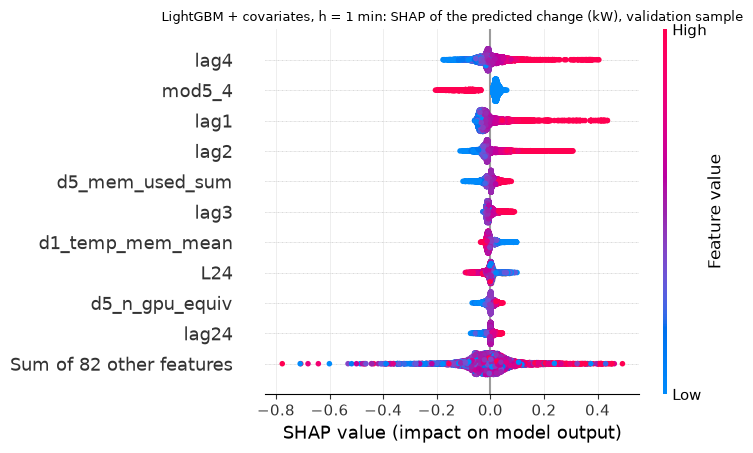

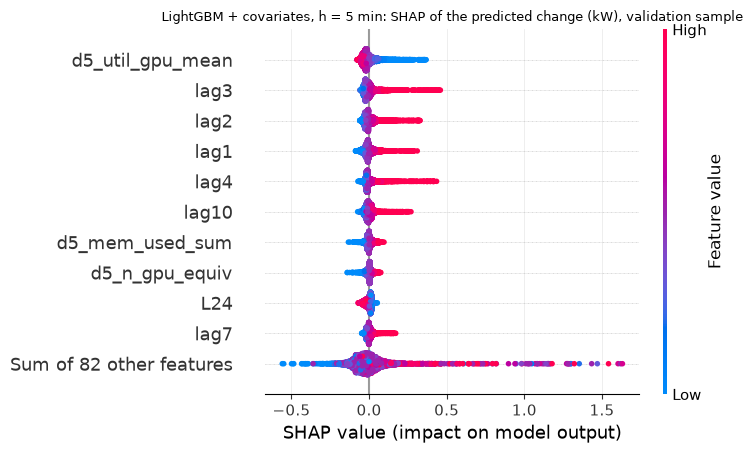

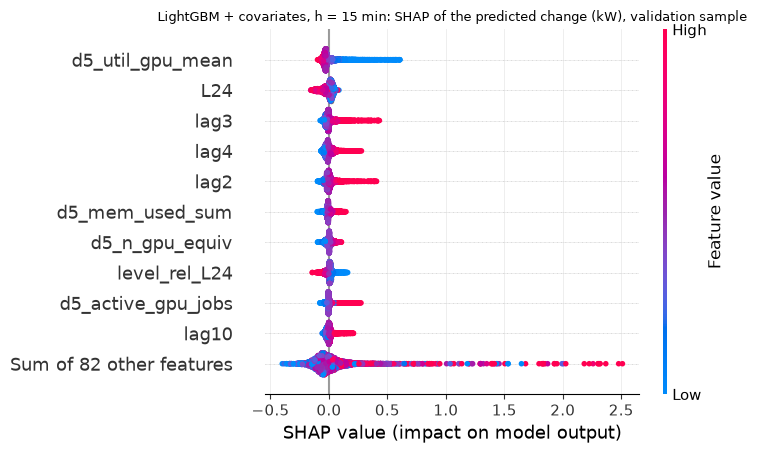

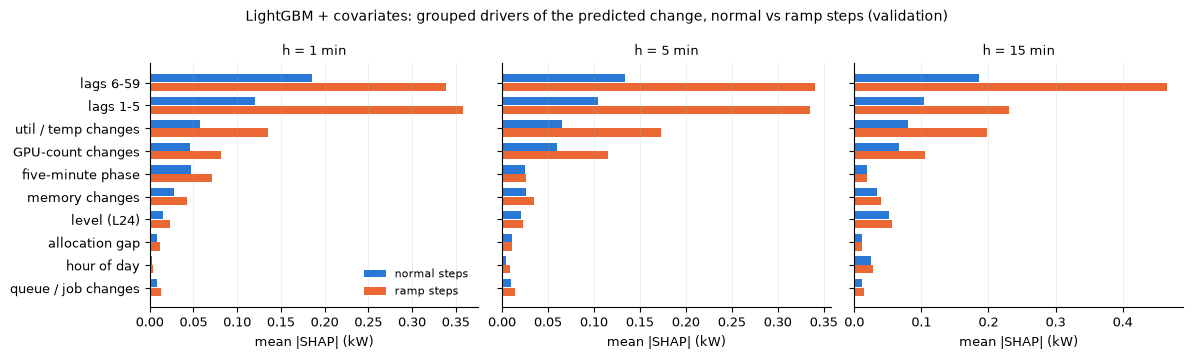

In [6]:
# Cell 6: figures: beeswarm (lightgbm_cov, h = 1 / 5 / 15) and grouped importance on normal vs ramp steps
for h in HORIZONS:
    s = SH[("lightgbm_cov", h)]
    m = s["sample"]
    ex = shap.Explanation(values=s["vals"][m], base_values=s["base"][m], data=s["X"][m], feature_names=s["names"])
    plt.figure()
    shap.plots.beeswarm(ex, max_display=11, show=False)
    plt.title(f"LightGBM + covariates, h = {h} min: SHAP of the predicted change (kW), validation sample", fontsize=9)
    plt.gcf().set_size_inches(7.5, 4.6)
    plt.tight_layout(); plt.savefig(FIG / f"05_shap_beeswarm_h{h}.png", dpi=160, bbox_inches="tight"); plt.show()

groups = (GRP.filter((pl.col("model") == "lightgbm_cov") & (pl.col("steps") == "all")).group_by("group")
             .agg(pl.col("share").mean()).sort("share", descending=True)["group"].to_list())
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
y = np.arange(len(groups))
for ax, h in zip(axes, HORIZONS):
    for k, (lab, colr) in enumerate((("normal", "#2a78d6"), ("ramp", "#eb6834"))):
        v = [GRP.filter((pl.col("model") == "lightgbm_cov") & (pl.col("h") == h) & (pl.col("steps") == lab) & (pl.col("group") == g))["mean_abs_shap_kW"][0] for g in groups]
        ax.barh(y + (k - 0.5) * 0.38, v, 0.36, color=colr, label=f"{lab} steps")
    ax.set_title(f"h = {h} min", fontsize=9); ax.set_xlabel("mean |SHAP| (kW)"); ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, groups); axes[0].invert_yaxis(); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("LightGBM + covariates: grouped drivers of the predicted change, normal vs ramp steps (validation)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "06_shap_groups_normal_vs_ramp.png", dpi=160, bbox_inches="tight"); plt.show()


In [7]:
# Cell 7: summary JSON and checklist
summ = {"models": list(ARMS), "seed": 0, "split": "val", "n_random_sample": N_SAMPLE,
        "reproduction_max_abs_diff_kW": float(REPRO["max_abs_diff_kW"].max()),
        "top10": TOP.to_dicts(), "groups": GRP.to_dicts(), "covariate_share": cov_share.to_dicts(), "gain_agreement": agree}
(REP / "shap_summary.json").write_text(json.dumps(summ, indent=1, default=str))
print("DONE  [main] SHAP on LightGBM, top-10 features reported (reports/week7/shap_top10_val.csv)")
for h in HORIZONS:
    t = TOP.filter((pl.col("model") == "lightgbm_cov") & (pl.col("h") == h)).sort("rank")
    print(f"h={h:>2}: " + ", ".join(t["feature"].to_list()[:5]) + " ...")


DONE  [main] SHAP on LightGBM, top-10 features reported (reports/week7/shap_top10_val.csv)
h= 1: lag4, mod5_4, lag1, lag2, d5_mem_used_sum ...
h= 5: d5_util_gpu_mean, lag3, lag2, lag1, lag4 ...
h=15: d5_util_gpu_mean, L24, lag3, lag4, lag2 ...


In [9]:
# Cell 8: export outputs (save the notebook first with Cmd+S after cell 7 has finished, then run this cell)
%run ../src/tools/nb_outputs_to_md.py 25_week7_shap.ipynb


written 25_week7_shap_outputs.md | code cells 10 | figures 4 in 25_week7_shap_outputs_figures
